In [37]:
import numpy as np
import matplotlib.pyplot as plt

In [38]:
def lorentz(amplitude, center, fwhm, nu):
    half = (fwhm / 2)**2
    diff = (nu - center)**2
    return (amplitude * half) / (diff + half)

In [39]:
amplitude, center, fwhm = 200.0, 5.0, 1.0

nu = np.linspace(0, 10, 2000)
y = lorentz(amplitude, center, fwhm, nu)

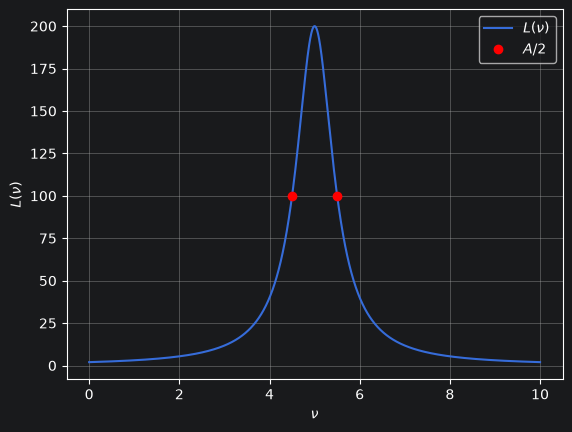

In [40]:
plt.plot(nu, y, label=r"$L(\nu)$")

x_half = center + np.array([-1, 1]) * fwhm / 2
y_half = lorentz(amplitude, center, fwhm, x_half)
plt.plot(x_half, y_half, "o", color="red", label=r"$A/2$")

plt.xlabel(r"$\nu$")
plt.ylabel(r"$L(\nu)$")
plt.legend()
plt.grid(True)
plt.show()

In [41]:
def add_noise(rng, expected, sigma_read):
    poisson = rng.poisson(lam=expected, size=expected.shape)
    gauss = rng.normal(0, sigma_read, size=expected.shape)
    return poisson + gauss

In [42]:
y = add_noise(rng=np.random.default_rng(0), expected=y, sigma_read=3)

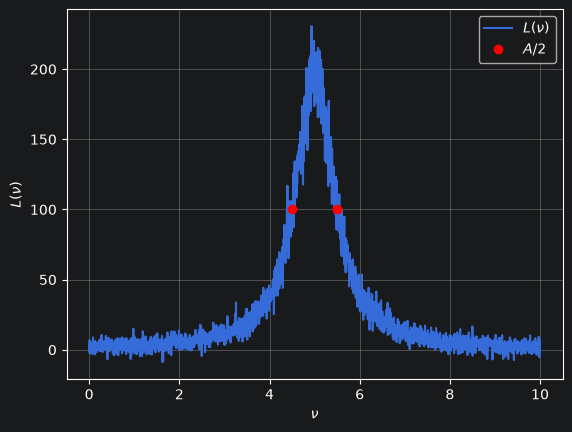

In [43]:
plt.plot(nu, y, label=r"$L(\nu)$")

x_half = center + np.array([-1, 1]) * fwhm / 2
y_half = lorentz(amplitude, center, fwhm, x_half)
plt.plot(x_half, y_half, "o", color="red", label=r"$A/2$")

plt.xlabel(r"$\nu$")
plt.ylabel(r"$L(\nu)$")
plt.legend()
plt.grid(True)
plt.show()

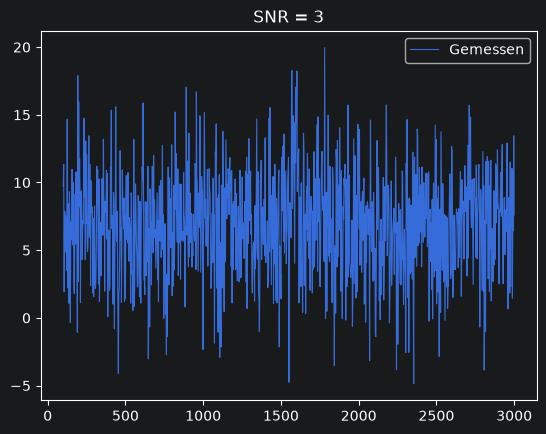

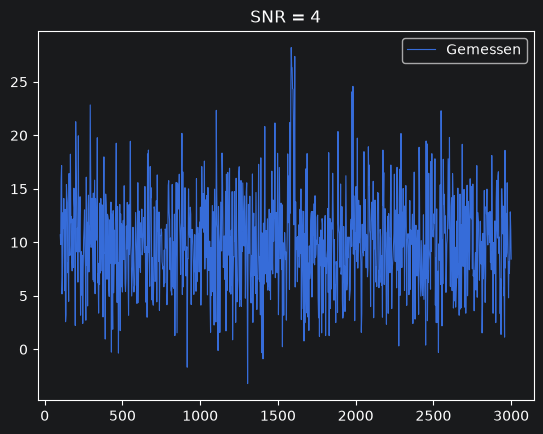

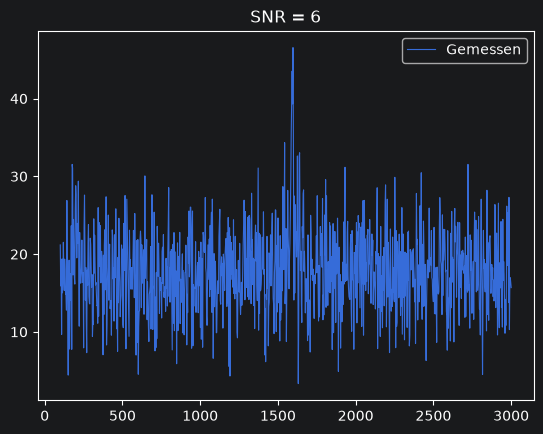

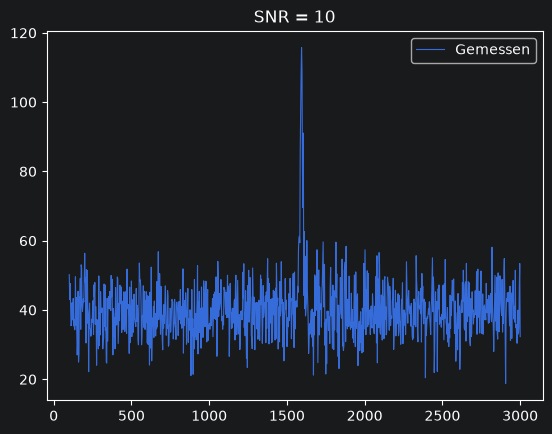

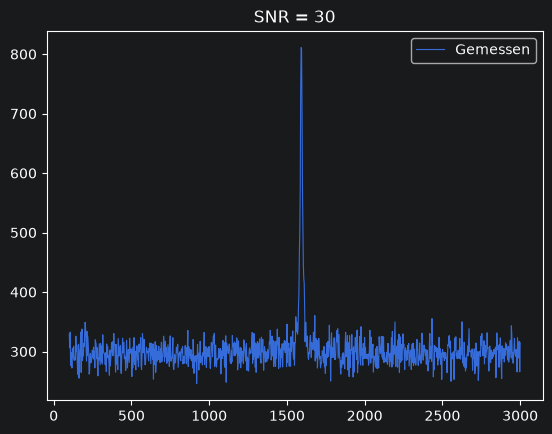

In [71]:
import src.raman_detection.generate as gen

import yaml

with open("../config.yaml") as f:
    cfg = yaml.safe_load(f)

axis = cfg["axis"]
nu = np.linspace(axis["nu_min"], axis["nu_max"], axis["n_points"])

for snr in [3, 4, 6, 10, 30]:
    counts, meta = gen.generate_spectrum(nu=nu, rng=np.random.default_rng(0), cfg=cfg, has_signal=True, snr=snr)
    plt.figure()
    plt.plot(nu, counts, lw=0.8, label="Gemessen")
    #plt.plot(nu, meta["expected"], lw=1.5, ls="--", label=r"Erwartungswert $\lambda$")
    plt.title(f"SNR = {snr}")
    plt.legend()
    plt.show()